In [1]:
#standard libraries
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme("talk")
import matplotlib.pyplot as plt

#sklearn for data manipulation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, normalize


import os
from datetime import datetime

#tensorflow for model building
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard, EarlyStopping

In [2]:
#load in data from directory
progenitor = pd.read_csv("progenitor.csv") #features
antesonic_time = pd.read_csv("antesonic_time.csv")   #make plot with this

In [3]:
#set up our 7 features X
progenitor.drop(["presn_mass","xi_1.75","xi_2.0","xi_2.75","xi_3.0", "Unnamed: 0"], axis = 1, inplace = True)
X = np.asarray(progenitor) #needs to be an array for tensorflow later on

In [4]:
#the features we are using
progenitor.head(5)

,zams,coremass_He,coremass_CO,coremass_Fe,xi_1.5,xi_2.25,xi_2.5
0,9.00,1.571818,1.402958,1.268346,0.005260,0.000041,0.000038
1,9.25,1.784207,1.453464,1.278493,0.028305,0.000054,0.000047
2,9.50,2.042073,1.503286,1.286028,0.093465,0.000091,0.000062
3,9.75,2.306592,1.558010,1.298881,0.305019,0.002272,0.000104
4,10.00,2.477523,1.610957,1.332185,0.455167,0.003974,0.000216


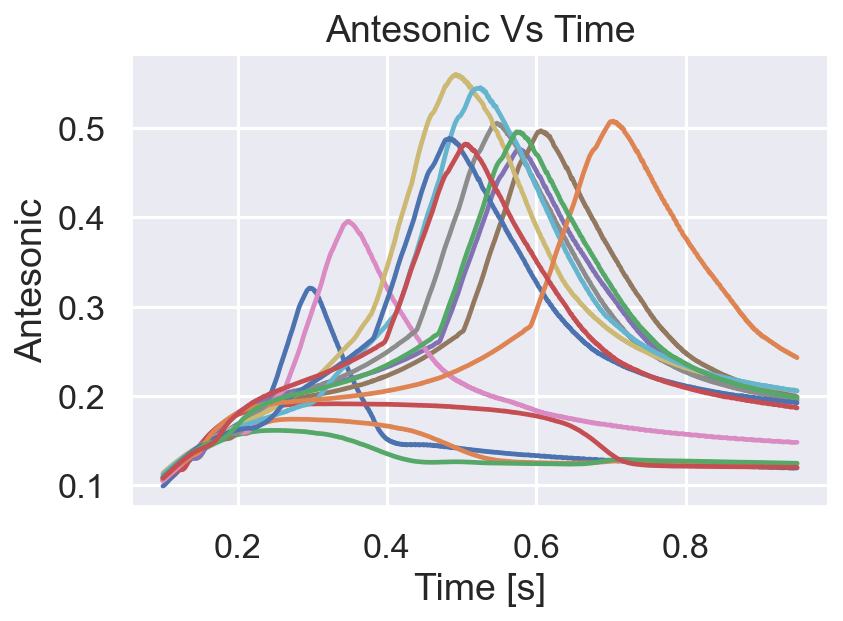

In [5]:
#get a sense of our data
col_names = antesonic_time.columns

plt.figure(dpi = 150)

for i,j in enumerate(col_names[1:]):
    if (i % 15 == 0):
        plt.plot(antesonic_time["time"],antesonic_time[j])
        plt.xlabel("Time [s]")
        plt.ylabel("Antesonic")
        plt.title("Antesonic Vs Time")

In [6]:
#extract Y for model building later on
time_feature = antesonic_time.pop("time")
Y = np.asarray(antesonic_time).T

Text(0.5, 1.0, 'Antesonic Vs Time')

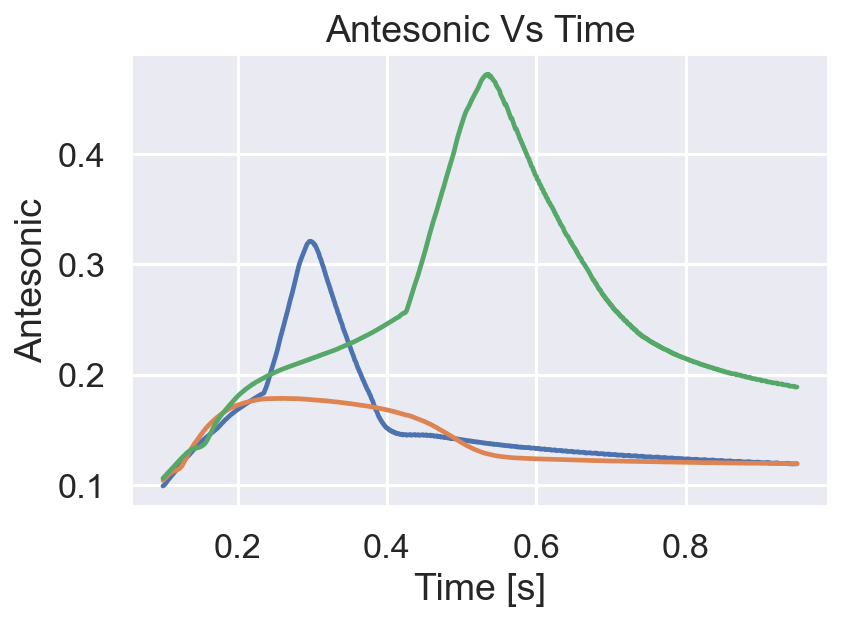

In [7]:
#visualize Y
%matplotlib inline

plt.figure(dpi=150)

plt.plot(time_feature, Y[0])
plt.plot(time_feature, Y[80])
plt.plot(time_feature, Y[50])
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Antesonic Vs Time")

In [8]:
# Preprocess the data (normalize)

X_nn = X.copy()
X_nn[:, 1:] = X_nn[:, 1:]

X_min = X_nn.min(axis=0)
X_max = X_nn.max(axis=0)

X_nn = (X_nn - X_min) / (X_max - X_min)

Y_nn = Y.copy()

Y_min = Y_nn.min(axis=0)
Y_max = Y_nn.max(axis=0)

Y_nn = (Y_nn - Y_min) / (Y_max - Y_min)

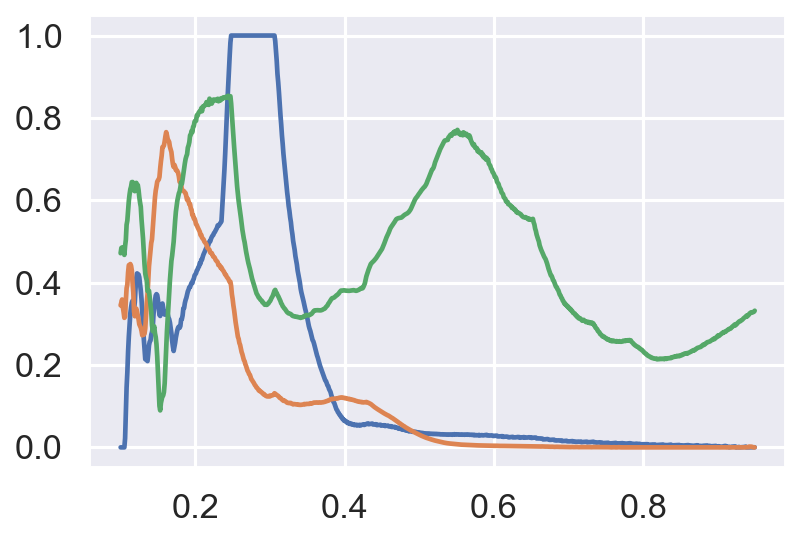

In [9]:
%matplotlib inline

plt.figure(dpi=150)

plt.plot(time_feature, Y_nn[0])
plt.plot(time_feature, Y_nn[80])
plt.plot(time_feature, Y_nn[50])

## Notice: I build the model without normalization!

In [10]:
# Split the data into training and validation sets

(X_train, 
 X_val,
 Y_train,
 Y_val) = train_test_split(X, Y, train_size=0.7, random_state=42, shuffle=True)

In [11]:
print(X_train.shape)
print(Y_train.shape)
print(X_val.shape)
print(Y_val.shape)

(140, 7)
(140, 850)
(60, 7)
(60, 850)


In [12]:
# Build the model

model = Sequential()
model.add(Dense(64, input_dim=X.shape[1], activation='softplus', kernel_initializer='VarianceScaling', ))
model.add(Dense(64, activation='softplus', kernel_initializer='VarianceScaling', ))
model.add(Dense(Y.shape[1], activation='softplus', kernel_initializer='VarianceScaling',))

model.compile(loss='mean_squared_error', optimizer='nadam')
print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                512       
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 850)               55250     
                                                                 
Total params: 59,922
Trainable params: 59,922
Non-trainable params: 0
_________________________________________________________________
None


In [13]:
def train(model, X_train, Y_train, X_val, Y_val, **kwargs):
    
    X_train = tf.convert_to_tensor(X_train)
    Y_train = tf.convert_to_tensor(Y_train)
    Train = (X_train, Y_train)

    X_val = tf.convert_to_tensor(X_val)
    Y_val = tf.convert_to_tensor(Y_val)
    Val = (X_val, Y_val)
    
    cur_date_str = datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
    logdir="logs/scalars/" + cur_date_str
    tensorboard_callback = TensorBoard(log_dir=logdir)
    checkpoints_dir = os.path.join('checkpoints', cur_date_str)
    os.makedirs(checkpoints_dir, exist_ok=True)
    checkpointer_best = ModelCheckpoint(monitor='val_loss', 
                                        filepath=os.path.join(checkpoints_dir, 'grid_weights_best.h5'), 
                                        save_best_only=True, save_weights_only=True)
    early_stopping = EarlyStopping(monitor='val_loss', 
                                   min_delta=0, patience=500, 
                                   verbose=0, mode='auto', baseline=None, 
                                   restore_best_weights=True)
    fit_kwargs = dict(validation_data=Val, 
                  epochs=400000, batch_size=128,
                  callbacks=[checkpointer_best, tensorboard_callback, early_stopping], 
                  verbose=0)
    fit_kwargs.update(kwargs)

    model.fit(*Train, **fit_kwargs)

In [14]:
%%time
train(model, X_train, Y_train, X_val, Y_val)

CPU times: total: 2min
Wall time: 1min 29s


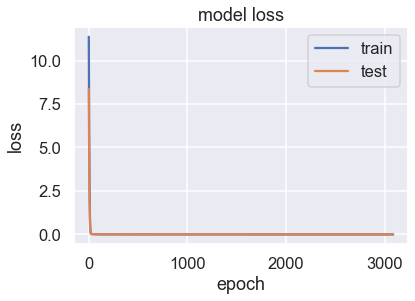

In [15]:
#https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'])
plt.show()

In [16]:
X_train[30]

array([13.6       ,  3.82816455,  2.66159798,  1.40407771,  0.91308885,
        0.15847139,  0.10597811])

In [17]:
#get the neural networks prediction
Y_nn_test = model(np.array([X_train[10], X_train[20], X_train[30]]), training = False)
# Y_emu_test = Y_nn_test * (Y_max - Y_min) + Y_min

## Note: Y[51] corresponds to having a Zams value of 16.5, Y[0] with 9, and Y[22] with 13.6

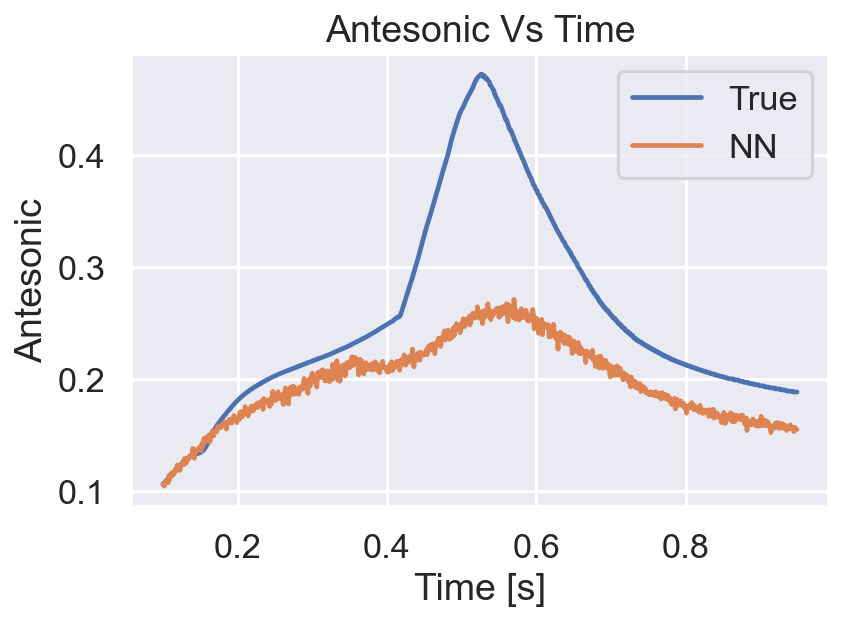

In [18]:
#plot the results
%matplotlib inline

plt.figure(dpi=150)

plt.plot(time_feature, Y[51], label = "True")
plt.plot(time_feature, Y_nn_test[0], label = "NN")
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Antesonic Vs Time")
plt.legend()

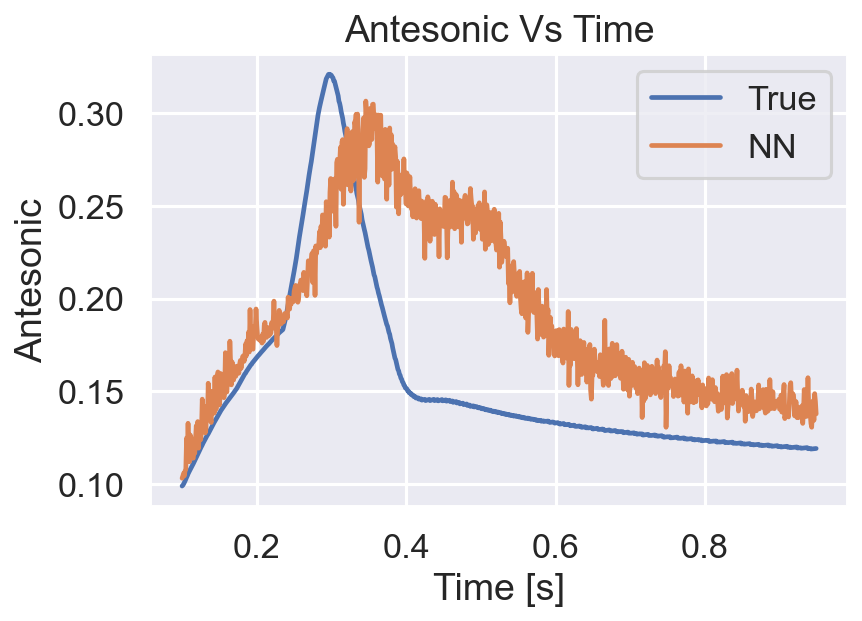

In [19]:
#plot the results
%matplotlib inline

plt.figure(dpi=150)

plt.plot(time_feature, Y[0], label = "True")
plt.plot(time_feature, Y_nn_test[1], label = "NN")
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Antesonic Vs Time")
plt.legend()

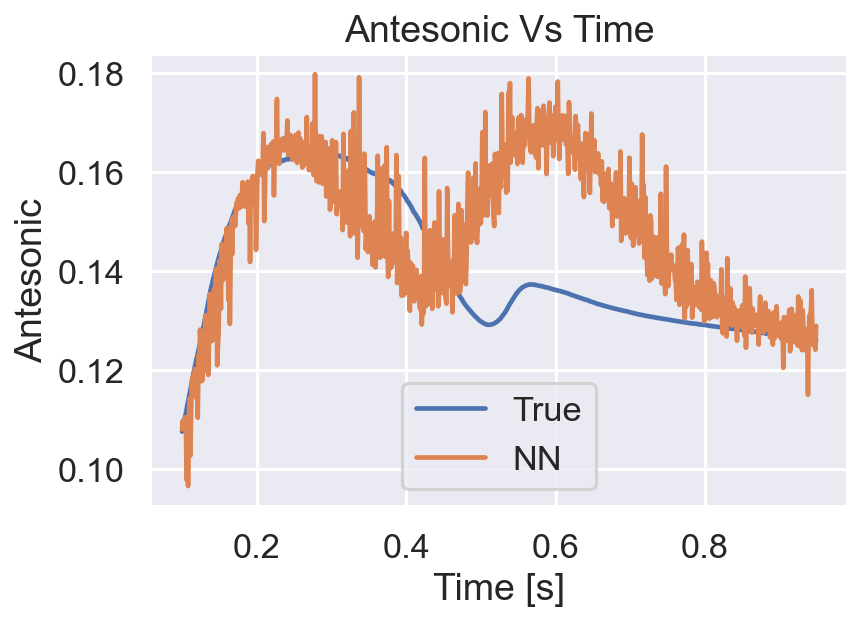

In [20]:
#plot the results
%matplotlib inline

plt.figure(dpi=150)

plt.plot(time_feature, Y[22], label = "True")
plt.plot(time_feature, Y_nn_test[2], label = "NN")
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Antesonic Vs Time")
plt.legend()